In [ ]:
#%pip install imbalanced-learn

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import laspy
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils import resample, class_weight
from scipy.spatial import cKDTree
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt

In [21]:
path_flo = "C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_10.laz"

las = laspy.read(path_flo)

# List all available attributes in the LAZ file
print("Available attributes in LAZ file:")
for spec in las.point_format.dimension_names:
    print("-", spec)


df = pd.DataFrame({
    "Classification": np.array(las.classification)
})


# total number of points
print("\nTotal number of points:\n", len(df))

display(df["Classification"].value_counts())

Available attributes in LAZ file:
- X
- Y
- Z
- intensity
- return_number
- number_of_returns
- synthetic
- key_point
- withheld
- overlap
- scanner_channel
- scan_direction_flag
- edge_of_flight_line
- classification
- user_data
- scan_angle
- point_source_id
- gps_time

Total number of points:
 8719136


Classification
2     4284521
6     3077079
5      851435
4      176527
1      142731
3       96945
7       79422
17      10476
Name: count, dtype: int64

In [ ]:
# Compute ground height (approximate lowest Z value)
ground_height = np.min(las.z)

# === Extract features ===
X = np.vstack((
    las.x,
    las.y,
    las.z,
    las.intensity,
    las.return_number,
    las.number_of_returns,
    las.z - ground_height,        # Height above ground
    las.scan_angle                
)).T.astype(np.float32)

# === Extract and map labels ===
unique_labels = np.unique(las.classification)
label_map = {label: idx for idx, label in enumerate(unique_labels)}
y = np.array([label_map[label] for label in las.classification]).astype(np.int64)

# === Standardize Features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# === Apply SMOTE for Balancing Classes ===
#smote = SMOTE(random_state=42)
#X_resampled, y_resampled = smote.fit_resample(X_scaled, y)

X_resampled, y_resampled = X_scaled, y


# -----------------------------------
# test centering each point cloud
N_POINTS = 1024
X_centered = X_resampled.copy()

# Subtract mean x, y, z from each point cloud
for i in range(0, len(X_centered), N_POINTS):
    chunk = X_centered[i:i+N_POINTS]
    centroid = np.mean(chunk[:, :3], axis=0)  # Only x, y, z
    X_centered[i:i+N_POINTS, :3] -= centroid
## ---------------------------------


# === sampling for faster training ===
X_sampled, y_sampled = resample(X_resampled, y_resampled, n_samples=4_000_000, random_state=42)


### Tensorflow

In [41]:
# === Build model function ===
def build_model(input_size, num_classes):
    return models.Sequential([
        layers.Input(shape=(input_size,)),

        layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Dense(256, kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Dense(256, kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Dense(num_classes, activation='softmax')
    ])

# === Stratified K-Fold Setup ===
kfold = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

# === Track fold results ===
fold_accuracies = []

best_model = None
best_acc = 0.0

class_weights_array = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_resampled),
    y=y_resampled
)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights_array)}

for fold, (train_idx, val_idx) in enumerate(kfold.split(X_sampled, y_sampled)):
    print(f"\nFold {fold + 1}")

    X_train_fold, X_val_fold = X_sampled[train_idx], X_sampled[val_idx]
    y_train_fold, y_val_fold = y_sampled[train_idx], y_sampled[val_idx]

    # Convert to TensorFlow tensors
    X_train_tf = tf.convert_to_tensor(X_train_fold, dtype=tf.float32)
    y_train_tf = tf.convert_to_tensor(y_train_fold, dtype=tf.int32)
    X_val_tf = tf.convert_to_tensor(X_val_fold, dtype=tf.float32)
    y_val_tf = tf.convert_to_tensor(y_val_fold, dtype=tf.int32)

    # Build a new model for each fold
    model = build_model(input_size=X_train_tf.shape[1], num_classes=len(np.unique(y_sampled)))

    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=0.0008, weight_decay=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Callbacks
    lr_scheduler = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
    early_stopping = callbacks.EarlyStopping(patience=15, restore_best_weights=True)

    # Train model
    model.fit(
        X_train_tf, y_train_tf,
        validation_data=(X_val_tf, y_val_tf),
        epochs=20,
        batch_size=512,
        callbacks=[lr_scheduler, early_stopping],
        verbose=2,
        class_weight=class_weights_dict
    )

    # Evaluate
    val_loss, val_accuracy = model.evaluate(X_val_tf, y_val_tf, verbose=0)
    fold_accuracies.append(val_accuracy)
    print(f"Fold {fold + 1} Accuracy: {val_accuracy:.4f}")

    # Save best model
    if val_accuracy > best_acc:
        best_acc = val_accuracy
        best_model = model


# Final summary
print(f"\nMean Accuracy across folds: {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")


Fold 1
Epoch 1/20
1954/1954 - 54s - 28ms/step - accuracy: 0.6015 - loss: 1.3097 - val_accuracy: 0.7192 - val_loss: 0.9337 - learning_rate: 8.0000e-04
Epoch 2/20
1954/1954 - 57s - 29ms/step - accuracy: 0.6497 - loss: 1.1516 - val_accuracy: 0.6877 - val_loss: 0.9694 - learning_rate: 8.0000e-04
Epoch 3/20
1954/1954 - 55s - 28ms/step - accuracy: 0.6635 - loss: 1.1026 - val_accuracy: 0.7189 - val_loss: 0.9091 - learning_rate: 8.0000e-04
Epoch 4/20
1954/1954 - 55s - 28ms/step - accuracy: 0.6682 - loss: 1.0756 - val_accuracy: 0.7184 - val_loss: 0.9003 - learning_rate: 8.0000e-04
Epoch 5/20
1954/1954 - 55s - 28ms/step - accuracy: 0.6752 - loss: 1.0572 - val_accuracy: 0.6837 - val_loss: 0.9695 - learning_rate: 8.0000e-04
Epoch 6/20
1954/1954 - 63s - 32ms/step - accuracy: 0.6774 - loss: 1.0446 - val_accuracy: 0.7071 - val_loss: 0.9413 - learning_rate: 8.0000e-04
Epoch 7/20
1954/1954 - 57s - 29ms/step - accuracy: 0.6827 - loss: 1.0327 - val_accuracy: 0.7059 - val_loss: 0.9391 - learning_rate: 8.

##### Test model on new file

In [42]:
path_flo_2 = "C:/Users/flori/Desktop/pa-1_data/kantonal_winterthur_1.laz"

# === Step 1: Load new LAS file ===
las_2 = laspy.read(path_flo_2)

# === Step 2: Compute features ===
ground_height_2 = np.min(las_2.z)

X_new = np.vstack((
    las_2.x,
    las_2.y,
    las_2.z,
    las_2.intensity,
    las_2.return_number,
    las_2.number_of_returns,
    las_2.z - ground_height_2,
    las_2.scan_angle
)).T.astype(np.float32)

# === Step 3: Standardize features using training scaler ===
X_new_scaled = scaler.transform(X_new)

# === Step 4: Predict with trained model ===
X_new_tensor = tf.convert_to_tensor(X_new_scaled, dtype=tf.float32)
y_pred_probs = best_model.predict(X_new_tensor, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# === Step 5 (optional): Map back to original class labels ===
# Inverse label_map to recover original class IDs (e.g. 2, 6, 17, etc.)
inv_label_map = {v: k for k, v in label_map.items()}
y_pred_original = np.array([inv_label_map[p] for p in y_pred])

In [43]:
# List all available attributes in the LAS file
print("Available attributes in LAS file:")
for spec in las_2.point_format.dimension_names:
    print("-", spec)



df = pd.DataFrame({
    "X": np.array(las_2.x),
    "Y": np.array(las_2.y),
    "Z": np.array(las_2.z),
    "Intensity": np.array(las_2.intensity),
    "Classification": np.array(las_2.classification)
})


# total number of points
print("\nTotal number of points:\n", len(df))

display(df["Classification"].value_counts())

Available attributes in LAS file:
- X
- Y
- Z
- intensity
- return_number
- number_of_returns
- synthetic
- key_point
- withheld
- overlap
- scanner_channel
- scan_direction_flag
- edge_of_flight_line
- classification
- user_data
- scan_angle
- point_source_id
- gps_time

Total number of points:
 12183994


Classification
6     6393191
2     4745915
5      425921
1      284059
4      124408
3      123857
7       75416
15      11227
Name: count, dtype: int64

**Report**

Accuracy on new data: 0.0062

Classification Report:


c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

     Class 1     0.0000    0.0000    0.0000    284059
     Class 2     0.0000    0.0000    0.0000   4745915
     Class 3     0.0000    0.0000    0.0000    123857
     Class 4     0.0000    0.0000    0.0000    124408
     Class 5     0.0000    0.0000    0.0000    425921
     Class 6     0.0000    0.0000    0.0000   6393191
     Class 7     0.0062    1.0000    0.0123     75416

    accuracy                         0.0062  12172767
   macro avg     0.0009    0.1429    0.0018  12172767
weighted avg     0.0000    0.0062    0.0001  12172767



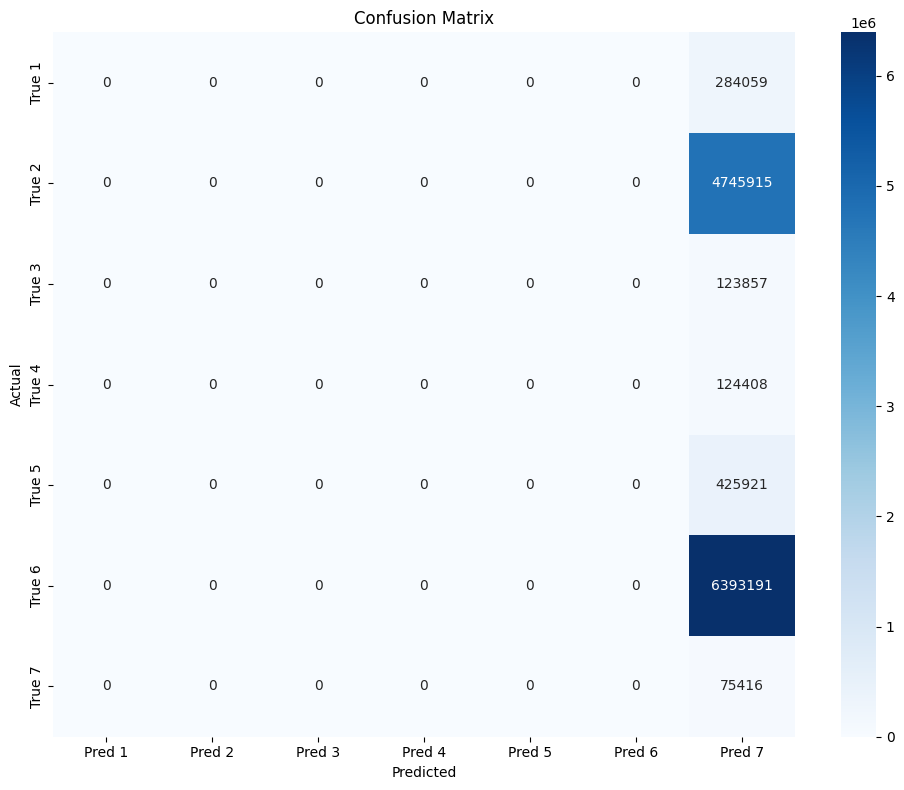

In [44]:
# === Filter out only those labels that were seen during training ===
valid_indices = [i for i, cls in enumerate(las_2.classification) if cls in label_map]
y_true_new = np.array([label_map[cls] for cls in las_2.classification[valid_indices]])
y_pred_new = y_pred[valid_indices]

# === Accuracy ===
acc = accuracy_score(y_true_new, y_pred_new)
print(f"Accuracy on new data: {acc:.4f}")

# === Classification report ===
print("\nClassification Report:")
# Determine actual unique labels in the evaluation set
labels_present = sorted(np.unique(y_true_new))

# Print classification report only for present classes
print(classification_report(
    y_true_new,
    y_pred_new,
    labels=labels_present,
    target_names=[f"Class {inv_label_map[i]}" for i in labels_present],
    digits=4
))


# === Confusion matrix ===
cm = confusion_matrix(y_true_new, y_pred_new, labels=labels_present)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"Pred {inv_label_map[i]}" for i in labels_present],
            yticklabels=[f"True {inv_label_map[i]}" for i in labels_present])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()



### PointNet

**reshape data**

In [23]:
# Parameters
N_POINTS = 1024
NUM_SAMPLES = len(X_sampled) // N_POINTS  # floor division to make full batches

# Trim data to make it divisible
X_trimmed = X_sampled[:NUM_SAMPLES * N_POINTS]
y_trimmed = y_sampled[:NUM_SAMPLES * N_POINTS]

# Reshape
X_pointcloud = X_trimmed.reshape(NUM_SAMPLES, N_POINTS, -1)
y_pointcloud = y_trimmed.reshape(NUM_SAMPLES, N_POINTS)  # each point has a label

**Model**

In [24]:
def build_pointnet_model(num_points, num_features, num_classes):
    inputs = tf.keras.Input(shape=(num_points, num_features))

    # Per-point MLP (shared weights)
    x = layers.Conv1D(64, 1, activation='relu')(inputs)
    x = layers.Conv1D(128, 1, activation='relu')(x)
    x = layers.Conv1D(1024, 1, activation='relu')(x)
    
    # Global feature (max pooling across points)
    global_feat = layers.GlobalMaxPooling1D()(x)
    
    # Repeat global features for each point
    global_feat = layers.RepeatVector(num_points)(global_feat)
    global_feat = layers.Concatenate()([x, global_feat])  # concat local + global

    # Another shared MLP
    x = layers.Conv1D(512, 1, activation='relu')(global_feat)
    x = layers.Conv1D(256, 1, activation='relu')(x)
    x = layers.Conv1D(num_classes, 1, activation='softmax')(x)

    model = models.Model(inputs=inputs, outputs=x)
    return model

**compile and train**

In [25]:
NUM_CLASSES = len(np.unique(y_sampled))
model = build_pointnet_model(num_points=N_POINTS, num_features=X_pointcloud.shape[2], num_classes=NUM_CLASSES)

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    metrics=['accuracy']
)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_pointcloud, y_pointcloud, test_size=0.2, random_state=42)

# Train
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=64,
    callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.5035 - loss: 1.3105 - val_accuracy: 0.8364 - val_loss: 0.5971
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.8595 - loss: 0.5170 - val_accuracy: 0.8953 - val_loss: 0.4003
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.8980 - loss: 0.3881 - val_accuracy: 0.9030 - val_loss: 0.3633
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.9057 - loss: 0.3549 - val_accuracy: 0.9088 - val_loss: 0.3383
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.9105 - loss: 0.3316 - val_accuracy: 0.9135 - val_loss: 0.3173
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.9142 - loss: 0.3126 - val_accuracy: 0.9159 - val_loss: 0.3013
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.9166 - loss: 0.2977 - val_accuracy: 0.9183 - val_loss: 0.2895
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.9193 - loss: 0.2860 - val_accuracy: 0.9200 - val_loss:

**visualize training progress**

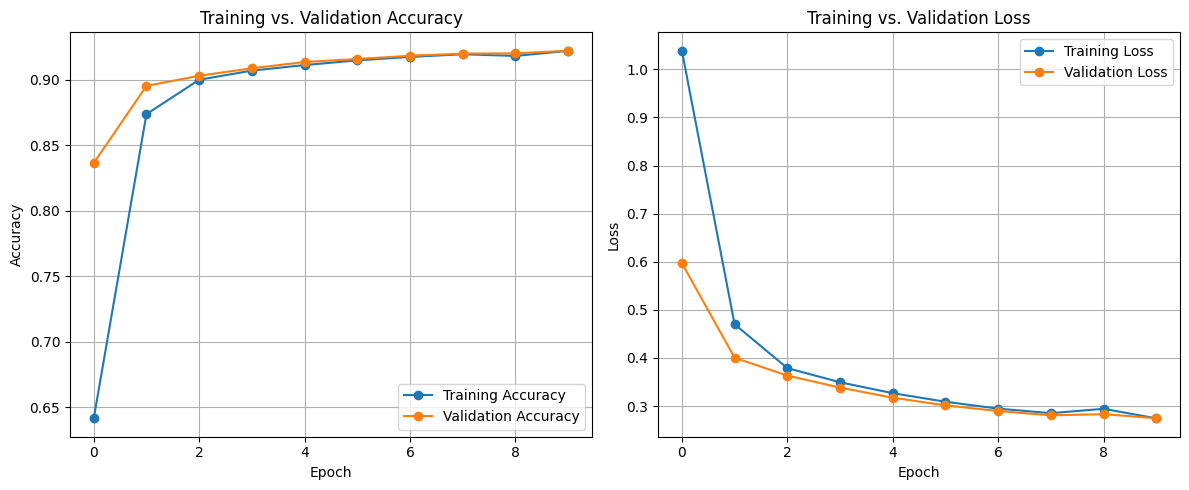

In [26]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Evaluation**

In [28]:
# Predict on test set
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=-1)

# Flatten for evaluation
y_true_flat = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

print("Accuracy:", accuracy_score(y_true_flat, y_pred_flat))
print(classification_report(y_true_flat, y_pred_flat))


13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step
Accuracy: 0.9221772098785166
              precision    recall  f1-score   support

           0       0.52      0.06      0.10      6620
           1       0.94      0.99      0.96    197015
           2       0.33      0.00      0.00      4395
           3       0.57      0.46      0.51      8062
           4       0.86      0.88      0.87     39150
           5       0.94      0.95      0.94    140979
           6       0.73      0.46      0.57      3666
           7       0.00      0.00      0.00       497

    accuracy                           0.92    400384
   macro avg       0.61      0.48      0.49    400384
weighted avg       0.91      0.92      0.91    400384



c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


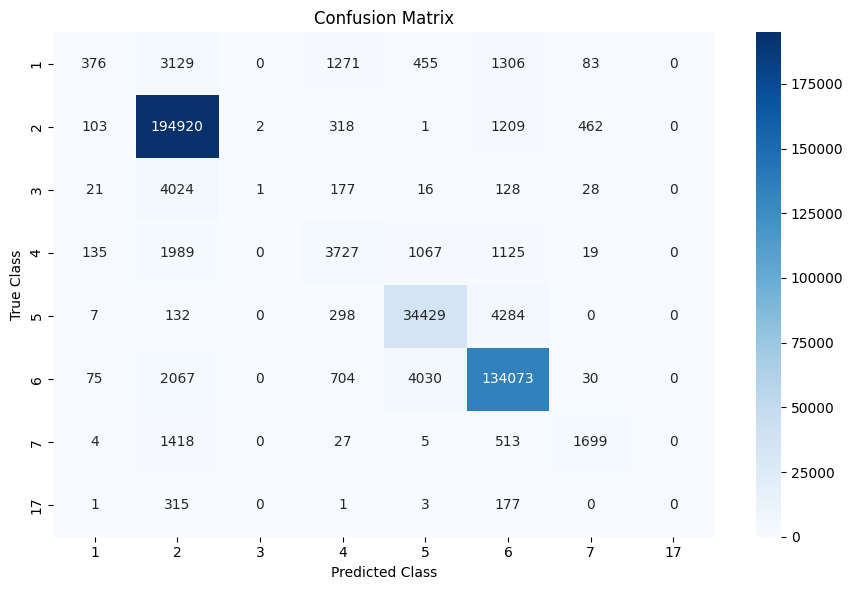

In [33]:
# Flatten labels
y_true = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

#### test on new unseen datafile

In [29]:
# === Load and inspect the new LAS file ===
path_flo_2 = "C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_2.laz"
las_2 = laspy.read(path_flo_2)

print("New file classes:", np.unique(las_2.classification))

df2 = pd.DataFrame({
    "Classification": np.array(las_2.classification)
})

# Value count per class
display(df2["Classification"].value_counts())

# === Feature extraction ===
ground_height_2 = np.min(las_2.z)

X2 = np.vstack((
    las_2.x,
    las_2.y,
    las_2.z,
    las_2.intensity,
    las_2.return_number,
    las_2.number_of_returns,
    las_2.z - ground_height_2,
    las_2.scan_angle
)).T.astype(np.float32)

# === Label mapping ===
y2_raw = np.array(las_2.classification)
y2_mapped = np.array([label_map.get(label, -1) for label in y2_raw])  # unseen class (e.g. 15) → -1

# Filter out unseen labels
mask_known = y2_mapped != -1
X2 = X2[mask_known]
y2_mapped = y2_mapped[mask_known]

# === Normalize === (use same scaler from training)
X2_scaled = scaler.transform(X2)


New file classes: [ 1  2  3  4  5  6  7 17]


Classification
2     3606443
6     2312505
5      823094
4      197726
1      137979
3       48155
7        9758
17       7138
Name: count, dtype: int64

In [30]:
# === Reshape to mini point clouds ===
N_POINTS = 1024
NUM_SAMPLES = len(X2_scaled) // N_POINTS

X2_trimmed = X2_scaled[:NUM_SAMPLES * N_POINTS]
y2_trimmed = y2_mapped[:NUM_SAMPLES * N_POINTS]

X2_pointcloud = X2_trimmed.reshape(NUM_SAMPLES, N_POINTS, -1)
y2_pointcloud = y2_trimmed.reshape(NUM_SAMPLES, N_POINTS)

# === Center each point cloud to origin ===
X2_pointcloud[:, :, :3] -= np.mean(X2_pointcloud[:, :, :3], axis=1, keepdims=True)


# === Predict ===
y2_pred_probs = model.predict(X2_pointcloud)
y2_pred_labels = np.argmax(y2_pred_probs, axis=-1)

# === Flatten and evaluate ===
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y2_true_flat = y2_pointcloud.flatten()
y2_pred_flat = y2_pred_labels.flatten()

print("Accuracy on new file:", accuracy_score(y2_true_flat, y2_pred_flat))
print(classification_report(y2_true_flat, y2_pred_flat))


218/218 ━━━━━━━━━━━━━━━━━━━━ 77s 356ms/step
Accuracy on new file: 0.00661122311827957


c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           0       0.01      0.00      0.00    137979
           1       0.00      0.00      0.00   3606222
           2       0.00      0.00      0.00     48143
           3       0.00      0.00      0.00    197688
           4       0.98      0.04      0.08    822967
           5       0.33      0.00      0.00   2312505
           6       0.00      1.00      0.00      9758
           7       0.00      0.00      0.00      7138

    accuracy                           0.01   7142400
   macro avg       0.16      0.13      0.01   7142400
weighted avg       0.22      0.01      0.01   7142400



c:\Users\flori\anaconda3\envs\PA-1\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### Confusion matrix

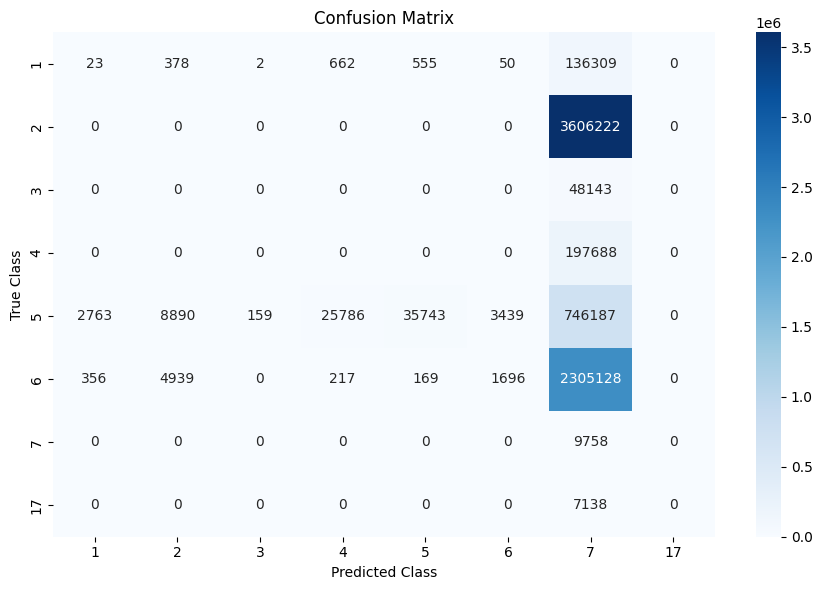

In [34]:
# Flatten labels
y2_true = y2_true_flat
y2_pred_flat = y2_pred_labels.flatten()

# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y2_true, y2_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()